In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df_alunos = pd.read_csv("alunos_senai_sig.csv")

GRÁFICO EM PIZZA - CONTAGEM DE CURSOS

Curso
Banco de Dados    10
Design            15
Java              15
Python            20
dtype: int64


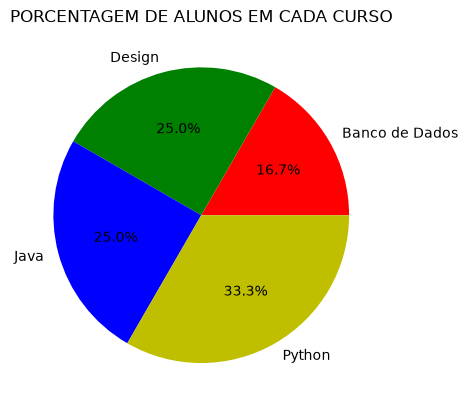

In [38]:
contagem_de_cursos = df_alunos.groupby("Curso").size()
print(contagem_de_cursos)

pizza = plt.pie(
    contagem_de_cursos,
    labels=contagem_de_cursos.index,
    autopct='%1.1f%%',
    colors=["r", "g", "b", "y"]
)

plt.title("PORCENTAGEM DE ALUNOS EM CADA CURSO")
plt.show()

GRAFICO DE MÉDIA DE CADA CURSO

Curso
Design            7.333333
Banco de Dados    7.130000
Java              6.966667
Python            6.115000
Name: Media_Final, dtype: float64


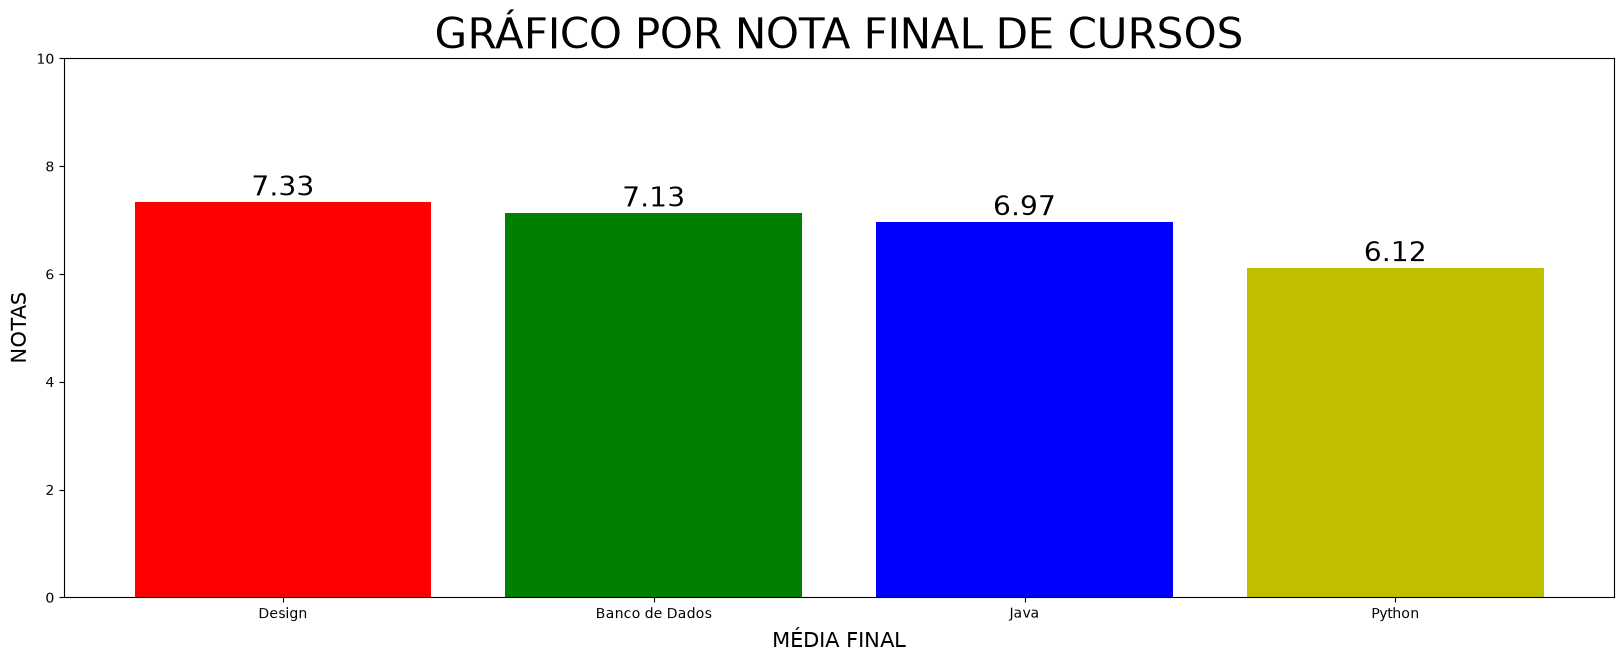

In [39]:
media_por_curso = df_alunos.groupby("Curso")["Media_Final"].mean().sort_values(ascending=False)

print(media_por_curso)

plt.figure(figsize=(20,7))

barra = plt.bar(
    media_por_curso.index,
    media_por_curso,
    color=["r", "g", "b", "y"]
)

#plt.title = ("MÉDIAS POR TURMA")
#plt.ylabel =  ("NOTAS")
#plt.xlabel = ("MÉDIA FINAL")
#plt.show()
#print(type(barra))

for coluna in barra:
    yvalor = coluna.get_height()

    plt.text(
        coluna.get_x() + coluna.get_width() / 2,
        yvalor,
        f"{yvalor:.2f}",
        fontsize=20,
        ha="center",
        va="bottom"
    )


plt.title ("GRÁFICO POR NOTA FINAL DE CURSOS", fontsize=30)
plt.ylabel  ("NOTAS", fontsize=15)
plt.xlabel ("MÉDIA FINAL", fontsize=15)
plt.ylim(0,10)


plt.show()


MÉDIA DE NOTAS INDIVIDUAIS POR ALUNOS DO CURSO

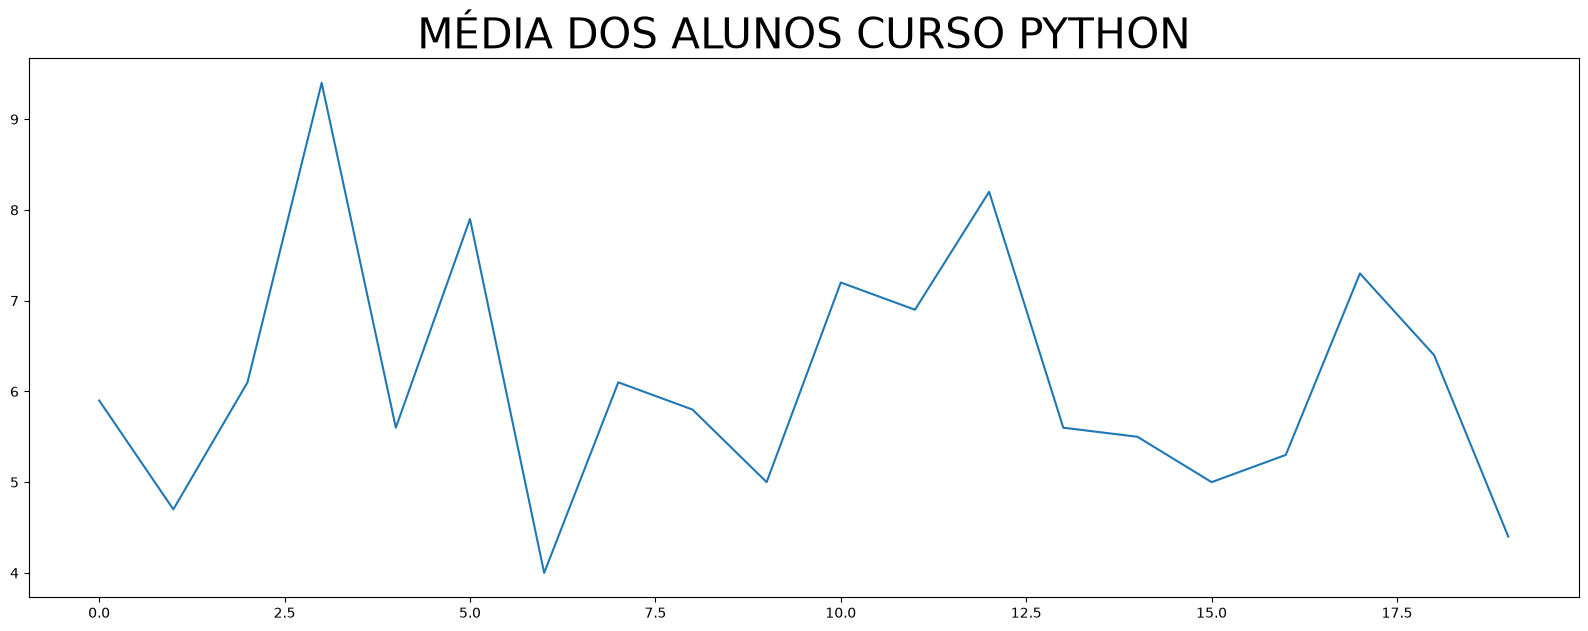

In [40]:
notas_python = df_alunos[
    df_alunos["Curso"] == "Python"
].reset_index(drop=True)


#print(notas_python)

plt.figure(figsize=(20,7))


plt.plot(notas_python.index,
         notas_python["Media_Final"],

)


plt.title("MÉDIA DOS ALUNOS CURSO PYTHON",fontsize=30)
#plt.savefig("media_final_alunos_curso_python.png")


plt.show()



LIDANDO COM SUBPLOTS

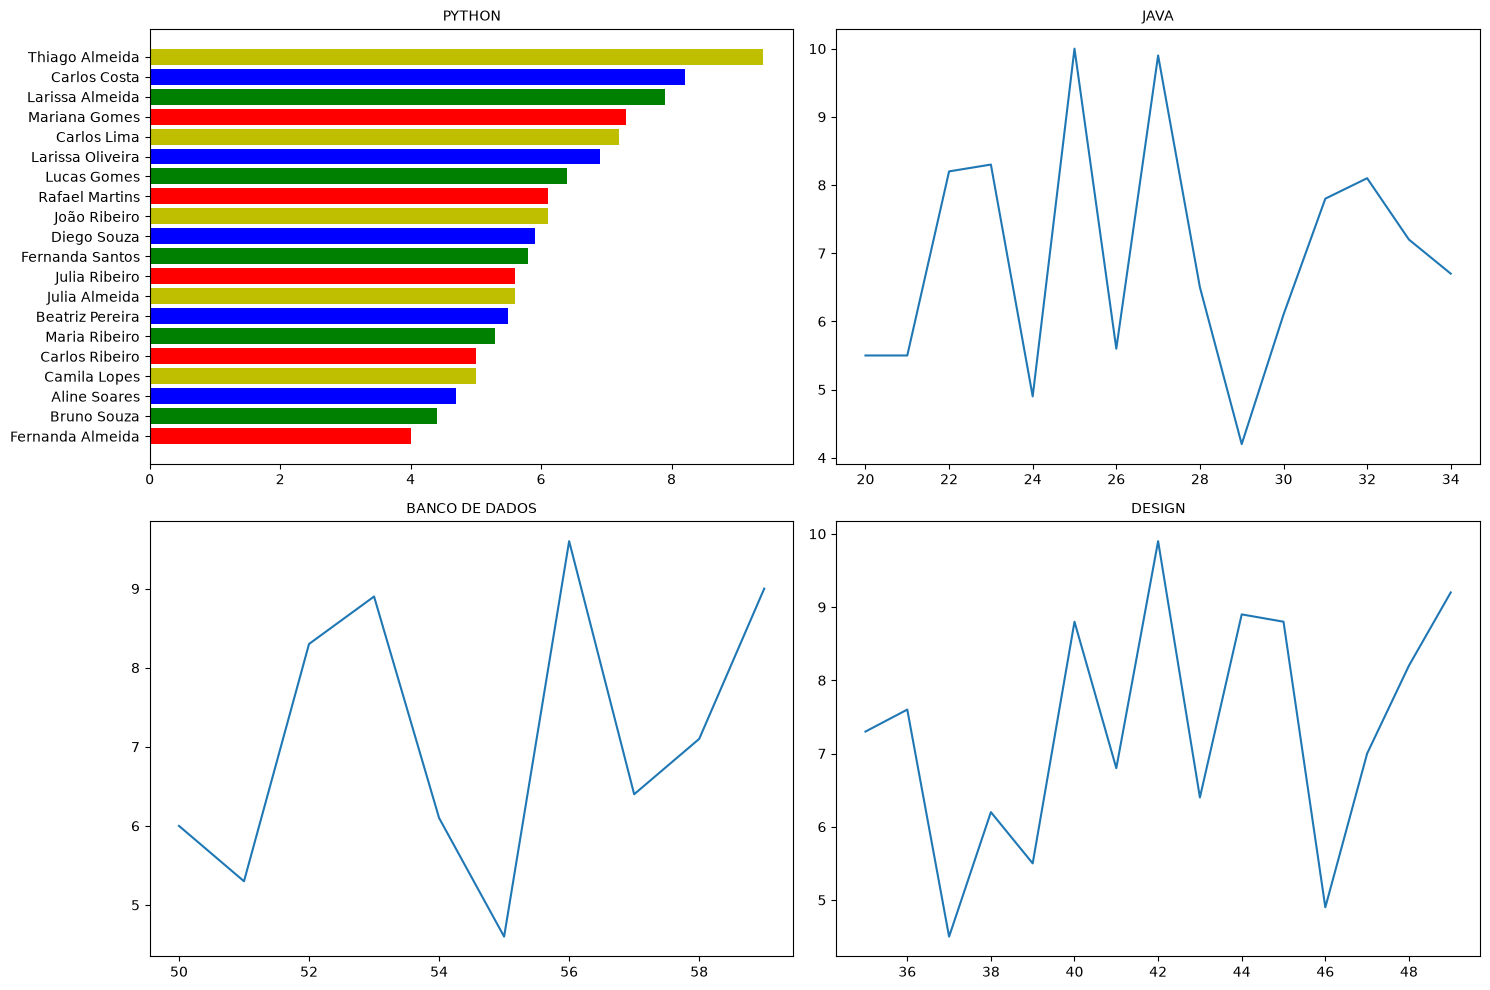

In [60]:
fig, axs = plt.subplots(2, 2, figsize=(15,10))

#[0,0] [0,1]
#[1,0] [1,1]


df_python = df_alunos[df_alunos["Curso"] == "Python"].sort_values(by="Media_Final")
df_java = df_alunos[df_alunos["Curso"] == "Java"]
df_bd = df_alunos[df_alunos["Curso"] == "Banco de Dados"]
df_design = df_alunos[df_alunos["Curso"] == "Design"]

axs[0,0].barh(df_python["Nome"],
              df_python["Media_Final"],
              color=["r", "g", "b", "y"],)
axs[0,0].set_title("PYTHON", fontsize=10)

axs[0,1].plot(df_java.index, df_java["Media_Final"])
axs[0,1].set_title("JAVA", fontsize=10)

axs[1,0].plot(df_bd.index, df_bd["Media_Final"])
axs[1,0].set_title("BANCO DE DADOS", fontsize=10)

axs[1,1].plot(df_design.index, df_design["Media_Final"])
axs[1,1].set_title("DESIGN", fontsize=10)

plt.tight_layout()

fig.savefig("media_final_alunos_cursos.png")


plt.show()